# 04 · Diagnóstico y pruebas

[Índice del frontend](README.md) · [Anterior · Series, historial y CSV](03_series_historial_y_csv.ipynb)

El diagnóstico empieza por determinar el último punto que responde. La carga de la página verifica el
servidor de archivos. La ruta de sesión verifica que las peticiones llegan a la API. La conexión SSE
verifica que el navegador puede recibir eventos. La presencia de datos requiere además un dispositivo
con mediciones disponibles.

Estas prácticas usan el panel y las herramientas del navegador. Usa una cuenta de prueba en un entorno
de desarrollo. Examina los estados y los códigos HTTP sin guardar contraseñas ni cookies en capturas.

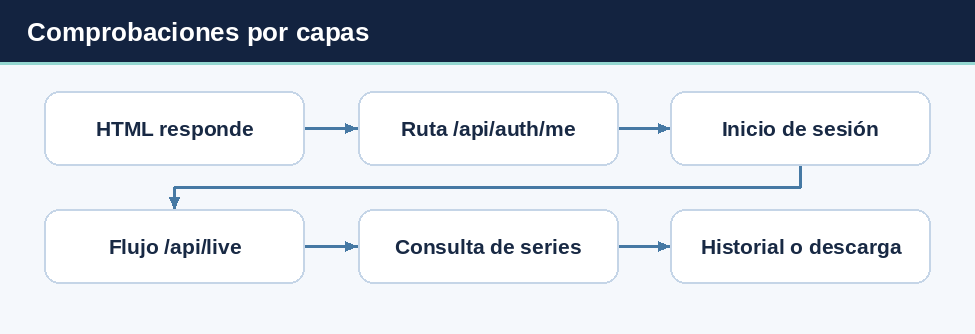

## Síntomas comunes

| Síntoma | Qué revisar | Resultado esperado |
| --- | --- | --- |
| La terminal no reconoce `vite`. | Ejecuta `npm ci` desde `ESP32/frontend`. Revisa el error previo y la versión de Node. | npm encuentra Vite en `node_modules`. |
| Vite avisa que el puerto está ocupado. | Revisa el proceso que ya usa 5173 o ejecuta Vite con otro puerto y abre el URL que imprime. | El navegador abre la instancia que acabas de iniciar. |
| Se abre el formulario y dice que no se pudo conectar. | Revisa `/api/auth/me` en Red. Confirma el destino del proxy y que la API inició. | Sin sesión válida devuelve `401`. |
| La API rechaza una cuenta. | Distingue `401` o `422` en `/api/auth/login`. Revisa que la cuenta exista y que los datos se ingresen en el formulario. | `200` al iniciar sesión con una cuenta válida. |
| La cuenta funciona con un URL y el otro pide iniciar sesión. | Comprueba si cambiaste de `localhost` a `127.0.0.1` o si la cookie se configuró para HTTPS. | Acceso y consultas usan el mismo host y el protocolo previsto. |
| **Reconectando al panel** durante varios segundos. | Revisa `/api/live` y `/api/auth/me` en Red. Puede ser conexión interrumpida o sesión expirada. | Con sesión válida, `/api/live` permanece abierto y recibe eventos. |
| **MQTT desconectado** con sesión válida. | Comprueba si el último snapshot tiene `broker_connected: false`. | El texto indica si la conexión HTTP funciona mientras faltan datos aguas arriba. |
| Hay tarjetas con datos y una métrica sin línea. | Prueba un periodo mayor y revisa `points` y los valores de esa métrica. | La serie usa muestras fechadas y representa huecos donde faltan valores. |
| La tabla tiene datos y Exportar CSV aparece inactivo. | Confirma que las fechas editadas estén aplicadas y que terminó la carga. | La URL de descarga refleja el dispositivo y los filtros aplicados. |
| Preview muestra cambios antiguos. | Compila de nuevo y abre el puerto de preview. Revisa qué `index.html` está sirviendo el proceso. | `dist` contiene los recursos de la última compilación. |

## Pruebas manuales de la interfaz

1. Abre el panel sin sesión. Espera el formulario y confirma que `GET /api/auth/me` devolvió `401`.
2. Inicia sesión. Confirma que la vista general aparece y que `/api/live` figura como flujo abierto con
   tipo `text/event-stream`.
3. Con un dispositivo disponible, guarda la selección y cambia de métrica. Comprueba que el valor y
   unidad del gráfico cambian. Cambia después de periodo y observa el parámetro `period` en Red.
4. Abre Historial e introduce Desde posterior a Hasta. Confirma el mensaje de validación. Corrige el
   rango, aplica y comprueba los parámetros `start`, `end` y `page`.
5. Con datos suficientes, cambia de página y descarga el CSV. Revisa que el enlace use el dispositivo y
   las fechas activas y que la tabla muestre el rango de filas visible.
6. Reduce el ancho del navegador. Navega mediante Tab entre el selector, los botones y los filtros.
   Comprueba que la tabla pueda desplazarse y que el foco sea visible.
7. Cierra sesión. Verifica que se cierre el flujo SSE y vuelva el formulario.

Anota el URL de inicio usado, el dispositivo, los filtros y el estado observado. Eso vuelve reproducible
el reporte incluso cuando las lecturas de la pantalla cambian con el tiempo.

## Trazar un error con un ejemplo

Imagina que el HTML carga bien y al iniciar sesión aparece **No se pudo iniciar sesión**. Identifica el
código en Red. Un `502` de un servidor intermedio significa que la petición llegó al proxy y ese servidor
recibió una respuesta inválida del servicio de destino. Un `401` significa que la API respondió con una negativa de autenticación.
Un error sin estado HTTP puede indicar que se perdió la conexión antes de tener respuesta. Estas pistas
sitúan el problema en capas distintas aunque el formulario siga siendo el mismo.

Este comando consulta solamente el estado de la ruta por el proxy. Se ejecuta con Vite activo. Es útil
cuando quieres comprobar el enlace desde una terminal sin manejar cookies ni credenciales.

```bash
curl -sS -o /dev/null -w '%{http_code}\n' http://127.0.0.1:5173/api/auth/me
```

La pestaña Consola ayuda a detectar errores de JavaScript como ausencia de un campo en un objeto.
La pestaña Red ayuda a revisar respuestas, tiempos, contenido de las consultas y actividad de SSE.
Para las interacciones visuales y accesibilidad, usa el inspector de elementos y el modo de pantalla
adaptable.

## Cierre de una modificación

Una compilación limpia verifica que el plugin de Svelte procese los componentes, que los imports
resuelvan y que se generen HTML, CSS y JavaScript de entrega. El comando se ejecuta dentro de
`ESP32/frontend`.

```bash
npm run build
```

Repite en el panel el recorrido que toca tu cambio y la consulta de sesión. Si trabajaste en gráficos,
comprueba una muestra numérica igual a cero, un hueco y un cambio de periodo. Si trabajaste en el
historial, prueba una página de resultados, un conjunto vacío y un intervalo invertido. Este recorrido
complementa la comprobación de compilación con el comportamiento que percibe la persona usuaria.

[Scripts configurados para el proyecto](../../frontend/package.json)

[Índice del frontend](README.md) · [Anterior · Series, historial y CSV](03_series_historial_y_csv.ipynb)